# Length of stay: Linear SVM

Linear support vector machine, one-vs-rest, with squared hinge loss. A kernel (RBF) SVM is impractical at ~127k training rows (training time grows quadratically or worse), so the linear version is used.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.svm import LinearSVC

model = LinearSVC(random_state=utils.SEED)
model

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


== Linear SVM ==  macro-F1 0.273  accuracy 0.459
              precision    recall  f1-score   support

     <1 week       0.48      0.86      0.61      4554
   1-4 weeks       0.39      0.17      0.24      3420
  1-3 months       0.42      0.17      0.24      2017
   3+ months       0.00      0.00      0.00       553

    accuracy                           0.46     10544
   macro avg       0.32      0.30      0.27     10544
weighted avg       0.41      0.46      0.39     10544

quadratic weighted kappa: 0.135


train accuracy 0.573  |  fit 16.7s  predict 0.0s


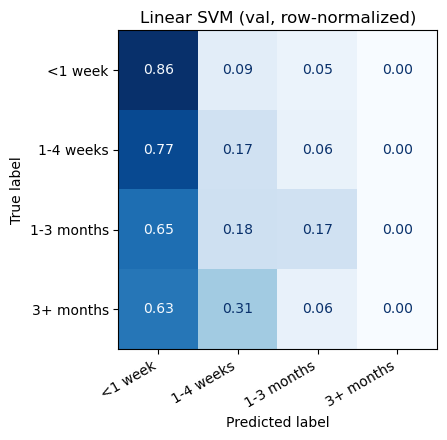

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Linear SVM",
                                           results_dir=RESULTS_DIR)

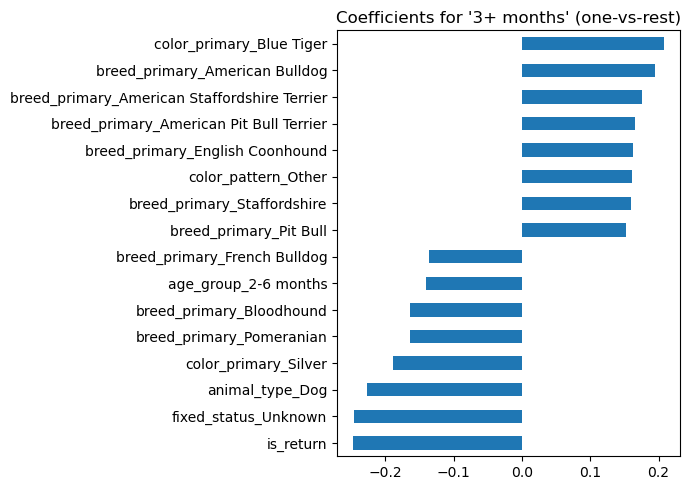

In [4]:
# Largest coefficients for the longest-stay class (features are standardized/one-hot,
# so magnitudes are roughly comparable; associations, not causes)
names = pipe.named_steps["pre"].get_feature_names_out()
model = pipe.named_steps["model"]
coef = pd.DataFrame(model.coef_, index=model.classes_, columns=names).T
top = coef["3+ months"].sort_values()
pd.concat([top.head(8), top.tail(8)]).plot(kind="barh", figsize=(7, 5),
                                           title="Coefficients for '3+ months' (one-vs-rest)")
plt.tight_layout(); plt.show()

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: margin penalty `C` and class weighting.

In [5]:
from scipy.stats import loguniform

base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'C': loguniform(1e-3, 10),
    'class_weight': [None, 'balanced'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Linear SVM (tuned)", n_iter=10, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Linear SVM (tuned): 10 candidates in 0.5 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.338
best params: {'C': 0.02161894240657444, 'class_weight': 'balanced'}


,C,class_weight,inner_val_f1_macro,mean_fit_time
0,0.021619,balanced,0.338181,16.576366
1,0.001007,balanced,0.338140,8.731274
2,0.679658,balanced,0.337195,26.590635
3,0.001707,balanced,0.337174,10.025928
4,2.136833,balanced,0.337145,26.890060
5,0.001681,balanced,0.337121,9.432614
6,0.005417,balanced,0.336495,12.764689
7,0.248104,None,0.254725,22.142261
8,0.060720,None,0.253865,18.655053
9,0.031489,None,0.253230,17.258723


== Linear SVM (tuned) ==  macro-F1 0.370  accuracy 0.422
              precision    recall  f1-score   support

     <1 week       0.56      0.55      0.55      4554
   1-4 weeks       0.42      0.26      0.32      3420
  1-3 months       0.34      0.42      0.38      2017
   3+ months       0.16      0.44      0.23       553

    accuracy                           0.42     10544
   macro avg       0.37      0.42      0.37     10544
weighted avg       0.45      0.42      0.43     10544

quadratic weighted kappa: 0.268


train accuracy 0.518  |  fit 9.2s  predict 0.0s


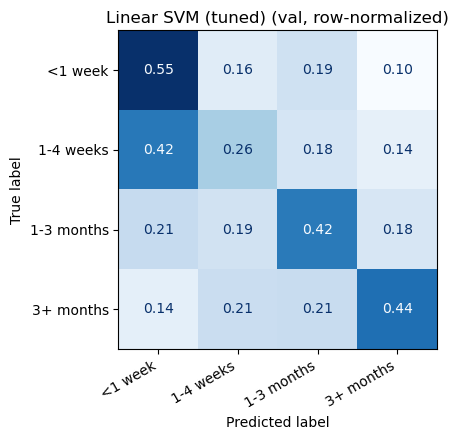

In [6]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Linear SVM (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [7]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Linear SVM,0.459,0.273,0.135,0.573,0.860,0.169,0.171,0.000
Linear SVM (tuned),0.422,0.370,0.268,0.518,0.547,0.256,0.419,0.439
